In [13]:
import pandas as pd
import numpy as np
df = pd.read_csv("datasets.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20770 entries, 0 to 20769
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              20770 non-null  float64
 1   name                            20770 non-null  str    
 2   host_id                         20770 non-null  int64  
 3   host_name                       20770 non-null  str    
 4   neighbourhood_group             20770 non-null  str    
 5   neighbourhood                   20763 non-null  str    
 6   latitude                        20763 non-null  float64
 7   longitude                       20763 non-null  float64
 8   room_type                       20763 non-null  str    
 9   price                           20736 non-null  float64
 10  minimum_nights                  20763 non-null  float64
 11  number_of_reviews               20763 non-null  float64
 12  last_review                     20763 non-n

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [15]:
df.isnull().sum()

id                                 0
name                               0
host_id                            0
host_name                          0
neighbourhood_group                0
neighbourhood                      7
latitude                           7
longitude                          7
room_type                          7
price                             34
minimum_nights                     7
number_of_reviews                  7
last_review                        7
reviews_per_month                  7
calculated_host_listings_count     7
availability_365                   7
number_of_reviews_ltm              7
license                            0
rating                             0
bedrooms                           0
beds                               0
baths                              0
dtype: int64

In [16]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,beds
count,2.077000e+04,2.077000e+04,20763.000000,20763.000000,20736.000000,20763.000000,20763.000000,20763.000000,20763.000000,20763.000000,20763.000000,20770.000000
mean,3.033858e+17,1.749049e+08,40.726821,-73.939179,187.714940,28.558493,42.610605,1.257589,18.866686,206.067957,10.848962,1.723592
std,3.901221e+17,1.725657e+08,0.060293,0.061403,1023.245124,33.532697,73.523401,1.904472,70.921443,135.077259,21.354876,1.211993
min,2.595000e+03,1.678000e+03,40.500314,-74.249840,10.000000,1.000000,1.000000,0.010000,1.000000,0.000000,0.000000,1.000000
25%,2.707260e+07,2.041184e+07,40.684159,-73.980755,80.000000,30.000000,4.000000,0.210000,1.000000,87.000000,1.000000,1.000000
50%,4.992852e+07,1.086990e+08,40.722890,-73.949597,125.000000,30.000000,14.000000,0.650000,2.000000,215.000000,3.000000,1.000000
75%,7.220000e+17,3.143997e+08,40.763106,-73.917475,199.000000,30.000000,49.000000,1.800000,5.000000,353.000000,15.000000,2.000000
max,1.050000e+18,5.504035e+08,40.911147,-73.713650,100000.000000,1250.000000,1865.000000,75.490000,713.000000,365.000000,1075.000000,42.000000


Bedroom categories

In [17]:
df['bedrooms'].value_counts()

bedrooms
1         13445
2          3606
Studio     1817
3          1394
4           345
5           112
6            29
7             9
9             6
8             5
15            1
14            1
Name: count, dtype: int64

Bathroom categories

In [18]:
df['baths'].value_counts()

baths
1                17026
2                 2083
1.5               1001
2.5                240
3                  171
0                   82
4                   69
3.5                 50
4.5                 18
Not specified       13
5                    6
6                    4
5.5                  2
6.5                  2
11.5                 1
7                    1
15.5                 1
Name: count, dtype: int64

Room types

In [19]:
df['room_type'].value_counts()

room_type
Entire home/apt    11555
Private room        8803
Shared room          293
Hotel room           112
Name: count, dtype: int64

Price distribution

In [20]:
df['price'].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

0.25     80.00
0.50    125.00
0.75    199.00
0.90    309.00
0.95    429.25
0.99    999.00
Name: price, dtype: float64

Duplicate records

In [21]:
df.duplicated().sum()

np.int64(12)

Expensive listings

In [22]:
df.nlargest(15, 'price')[['name', 'neighbourhood',
                          'room_type', 'bedrooms', 'price']]

,name,neighbourhood,room_type,bedrooms,price
3995,Rental unit in Brooklyn · ★4.48 · 1 bedroom · ...,Bedford-Stuyvesant,Private room,1,100000.0
5497,Rental unit in Brooklyn · ★4.33 · 1 bedroom · ...,Bedford-Stuyvesant,Private room,1,100000.0
906,Boutique hotel in New York · 1 bedroom · 1 bed...,Midtown,Private room,1,10000.0
2957,Rental unit in Queens · ★4.14 · 2 bedrooms · 2...,Long Island City,Entire home/apt,2,10000.0
3031,Loft in New York · ★4.50 · 4 bedrooms · 5 beds...,Murray Hill,Shared room,4,10000.0
3145,Boutique hotel in New York · ★3.40 · 1 bedroom...,Midtown,Private room,1,10000.0
4533,Boutique hotel in New York · ★3.33 · 1 bedroom...,Midtown,Private room,1,10000.0
6879,Rental unit in New York · Studio · 1 bed · 1 bath,Financial District,Entire home/apt,Studio,10000.0
10899,Home in Bronx · ★4.30 · 1 bedroom · 1 bed · 1 ...,Longwood,Private room,1,9994.0
11266,Hotel in NEW YORK · ★5.0 · 1 bedroom · 1 bed ·...,Theater District,Hotel room,1,7590.0


Inspecting duplicate records

In [23]:
df[df.duplicated(keep=False)].sort_values('id')

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,rating,bedrooms,beds,baths
20742,3.339399e+06,Rental unit in New York · ★4.73 · 1 bedroom · ...,2119276,Urban Furnished,Manhattan,West Village,40.732030,-74.006760,Entire home/apt,143.0,...,09/05/23,0.20,54.0,285.0,2.0,No License,4.73,1,1,1
20735,3.339399e+06,Rental unit in New York · ★4.73 · 1 bedroom · ...,2119276,Urban Furnished,Manhattan,West Village,40.732030,-74.006760,Entire home/apt,143.0,...,09/05/23,0.20,54.0,285.0,2.0,No License,4.73,1,1,1
3,3.857863e+06,Rental unit in New York · ★4.64 · 1 bedroom · ...,19902271,John And Catherine,Manhattan,Washington Heights,40.835600,-73.942500,Private room,120.0,...,17/09/23,1.38,2.0,363.0,12.0,No License,4.64,1,1,1
8,3.857863e+06,Rental unit in New York · ★4.64 · 1 bedroom · ...,19902271,John And Catherine,Manhattan,Washington Heights,40.835600,-73.942500,Private room,120.0,...,17/09/23,1.38,2.0,363.0,12.0,No License,4.64,1,1,1
20732,1.336161e+07,Rental unit in New York · ★4.89 · 2 bedrooms ·...,8961407,Jamie,Manhattan,Harlem,40.805700,-73.946250,Entire home/apt,397.0,...,08/09/23,1.08,3.0,274.0,3.0,No License,4.89,2,2,1
20739,1.336161e+07,Rental unit in New York · ★4.89 · 2 bedrooms ·...,8961407,Jamie,Manhattan,Harlem,40.805700,-73.946250,Entire home/apt,397.0,...,08/09/23,1.08,3.0,274.0,3.0,No License,4.89,2,2,1
20741,2.523473e+07,Rental unit in New York · ★4.41 · 1 bedroom · ...,1497427,Mara,Manhattan,Upper East Side,40.774030,-73.950580,Entire home/apt,120.0,...,31/03/23,0.26,2.0,364.0,1.0,No License,4.41,1,2,1
20734,2.523473e+07,Rental unit in New York · ★4.41 · 1 bedroom · ...,1497427,Mara,Manhattan,Upper East Side,40.774030,-73.950580,Entire home/apt,120.0,...,31/03/23,0.26,2.0,364.0,1.0,No License,4.41,1,2,1
4,4.089661e+07,Condo in New York · ★4.91 · Studio · 1 bed · 1...,61391963,Stay With Vibe,Manhattan,Murray Hill,40.751120,-73.978600,Entire home/apt,85.0,...,03/12/23,0.24,133.0,335.0,3.0,No License,4.91,Studio,1,1
9,4.089661e+07,Condo in New York · ★4.91 · Studio · 1 bed · 1...,61391963,Stay With Vibe,Manhattan,Murray Hill,40.751120,-73.978600,Entire home/apt,85.0,...,03/12/23,0.24,133.0,335.0,3.0,No License,4.91,Studio,1,1


Checking whether IDs are duplicated

In [24]:
df['id'].duplicated().sum()

np.int64(7567)

Inspecting repeated IDs

In [25]:
df[df['id'].duplicated(keep=False)][
    ['id', 'name', 'price']
].head(15)

,id,name,price
1,4.527754e+07,Rental unit in New York · ★4.67 · 2 bedrooms ·...,144.0
2,9.710000e+17,Rental unit in New York · ★4.17 · 1 bedroom · ...,187.0
3,3.857863e+06,Rental unit in New York · ★4.64 · 1 bedroom · ...,120.0
4,4.089661e+07,Condo in New York · ★4.91 · Studio · 1 bed · 1...,85.0
5,4.958498e+07,Rental unit in New York · ★5.0 · 1 bedroom · 1...,115.0
6,4.527754e+07,Rental unit in New York · ★4.67 · 2 bedrooms ·...,144.0
7,9.710000e+17,Rental unit in New York · ★4.17 · 1 bedroom · ...,187.0
8,3.857863e+06,Rental unit in New York · ★4.64 · 1 bedroom · ...,120.0
9,4.089661e+07,Condo in New York · ★4.91 · Studio · 1 bed · 1...,85.0
10,4.958498e+07,Rental unit in New York · ★5.0 · 1 bedroom · 1...,115.0


Unique IDs

In [26]:
df['id'].nunique()

13203

The price of the two $100,000 listings

In [27]:
df[df['price'] == 100000]

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,rating,bedrooms,beds,baths
3995,1.716029e+07,Rental unit in Brooklyn · ★4.48 · 1 bedroom · ...,110361431,Bobbi,Brooklyn,Bedford-Stuyvesant,40.69085,-73.93806,Private room,100000.0,...,20/10/23,0.96,2.0,346.0,10.0,No License,4.48,1,1,1
5497,6.050000e+17,Rental unit in Brooklyn · ★4.33 · 1 bedroom · ...,110361431,Bobbi,Brooklyn,Bedford-Stuyvesant,40.69254,-73.93636,Private room,100000.0,...,31/10/23,0.45,2.0,365.0,5.0,No License,4.33,1,1,1


In [28]:
df = pd.read_csv("datasets.csv", dtype={'id': str})

In [29]:
df['id'].nunique()

13203

In [30]:
df[df['id'].duplicated(keep=False)][
    ['id', 'name', 'price']
].head(15)

,id,name,price
1,45277537,Rental unit in New York · ★4.67 · 2 bedrooms ·...,144.0
2,9.71E+17,Rental unit in New York · ★4.17 · 1 bedroom · ...,187.0
3,3857863,Rental unit in New York · ★4.64 · 1 bedroom · ...,120.0
4,40896611,Condo in New York · ★4.91 · Studio · 1 bed · 1...,85.0
5,49584983,Rental unit in New York · ★5.0 · 1 bedroom · 1...,115.0
6,45277537,Rental unit in New York · ★4.67 · 2 bedrooms ·...,144.0
7,9.71E+17,Rental unit in New York · ★4.17 · 1 bedroom · ...,187.0
8,3857863,Rental unit in New York · ★4.64 · 1 bedroom · ...,120.0
9,40896611,Condo in New York · ★4.91 · Studio · 1 bed · 1...,85.0
10,49584983,Rental unit in New York · ★5.0 · 1 bedroom · 1...,115.0


Preprocessing

In [31]:
df = df.drop_duplicates()

df.shape

(20758, 22)

In [32]:
df[['neighbourhood_group',
    'neighbourhood',
    'room_type',
    'bedrooms',
    'beds',
    'baths',
    'price']].head(10)

,neighbourhood_group,neighbourhood,room_type,bedrooms,beds,baths,price
0,Brooklyn,Clinton Hill,Private room,1,1,Not specified,55.0
1,Manhattan,Hell's Kitchen,Entire home/apt,2,1,1,144.0
2,Manhattan,Chelsea,Entire home/apt,1,2,1,187.0
3,Manhattan,Washington Heights,Private room,1,1,1,120.0
4,Manhattan,Murray Hill,Entire home/apt,Studio,1,1,85.0
5,Manhattan,Hell's Kitchen,Entire home/apt,1,1,1,115.0
11,Manhattan,Hell's Kitchen,Entire home/apt,Studio,1,1,105.0
12,Manhattan,Hell's Kitchen,Entire home/apt,2,2,1,130.0
13,Brooklyn,Williamsburg,Private room,1,1,1,90.0
14,Brooklyn,Sunset Park,Entire home/apt,1,1,1,292.0


In [33]:
df[['neighbourhood_group',
    'neighbourhood',
    'room_type',
    'bedrooms',
    'beds',
    'baths',
    'price']].isnull().sum()

neighbourhood_group     0
neighbourhood           7
room_type               7
bedrooms                0
beds                    0
baths                   0
price                  34
dtype: int64

Rows with missing prices

In [34]:
df[df['price'].isnull()][
    ['neighbourhood', 'room_type', 'bedrooms', 'price']
].head(10)

,neighbourhood,room_type,bedrooms,price
15913,NaN,NaN,8,NaN
15914,NaN,NaN,1,NaN
15915,NaN,NaN,1,NaN
15916,NaN,NaN,1,NaN
15917,NaN,NaN,1,NaN
15918,NaN,NaN,2,NaN
15919,NaN,NaN,Studio,NaN
16017,East Flatbush,Private room,1,NaN
16018,Murray Hill,Entire home/apt,1,NaN
16019,Chelsea,Entire home/apt,Studio,NaN


Rows with missing neighbourhood or room type

In [35]:
df[df['neighbourhood'].isnull() |
   df['room_type'].isnull()][
    ['neighbourhood_group', 'neighbourhood',
     'room_type', 'price']
]

,neighbourhood_group,neighbourhood,room_type,price
15913,Manhattan,NaN,NaN,NaN
15914,Brooklyn,NaN,NaN,NaN
15915,Manhattan,NaN,NaN,NaN
15916,Brooklyn,NaN,NaN,NaN
15917,Brooklyn,NaN,NaN,NaN
15918,Brooklyn,NaN,NaN,NaN
15919,Manhattan,NaN,NaN,NaN


Bathroom entries

In [36]:
df['baths'].value_counts().head(15)

baths
1                17015
2                 2082
1.5               1001
2.5                240
3                  171
0                   82
4                   69
3.5                 50
4.5                 18
Not specified       13
5                    6
6                    4
5.5                  2
6.5                  2
11.5                 1
Name: count, dtype: int64

Creating ML Dataset

Selecting relevant columns

In [37]:
features = [
    'neighbourhood_group',
    'neighbourhood',
    'room_type',
    'bedrooms',
    'beds',
    'baths',
    'price'
]

df_ml = df[features].copy()

Removing rows without target prices

In [38]:
df_ml = df_ml.dropna(subset=['price'])

Converting unspecified bathrooms into missing values

In [39]:
df_ml['baths'] = df_ml['baths'].replace(
    'Not specified', np.nan
)

Checking the result

In [40]:
df_ml.isnull().sum()

neighbourhood_group     0
neighbourhood           0
room_type               0
bedrooms                0
beds                    0
baths                  13
price                   0
dtype: int64

In [41]:
df_ml.shape

(20724, 7)

In [42]:
df_ml['bedrooms'] = df_ml['bedrooms'].replace('Studio', '0')

df_ml['bedrooms'] = pd.to_numeric(df_ml['bedrooms'])

In [43]:
df_ml['baths'] = pd.to_numeric(df_ml['baths'])

In [44]:
df_ml.dtypes

neighbourhood_group        str
neighbourhood              str
room_type                  str
bedrooms                 int64
beds                     int64
baths                  float64
price                  float64
dtype: object

In [45]:
df_ml[['bedrooms', 'baths']].describe()

,bedrooms,baths
count,20724.000000,20711.000000
mean,1.306553,1.177804
std,0.876527,0.478963
min,0.000000,0.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,2.000000,1.000000
max,15.000000,15.500000


In [46]:
df_ml['baths'] = df_ml['baths'].fillna(
    df_ml['baths'].median()
)

In [47]:
df_ml['baths'].isnull().sum()

np.int64(0)

In [48]:
df_ml['neighbourhood'].nunique()

221

In [49]:
df_ml['neighbourhood_group'].value_counts()

neighbourhood_group
Manhattan        8031
Brooklyn         7694
Queens           3759
Bronx             949
Staten Island     291
Name: count, dtype: int64

In [50]:
df_ml['room_type'].value_counts()

room_type
Entire home/apt    11530
Private room        8791
Shared room          291
Hotel room           112
Name: count, dtype: int64

In [51]:
df_ml['neighbourhood'].value_counts().tail(15)

neighbourhood
Rossville                     2
Dongan Hills                  2
Richmondtown                  2
Huguenot                      2
Silver Lake                   2
Howland Hook                  2
Riverdale                     2
Westerleigh                   2
Todt Hill                     2
Willowbrook                   2
Navy Yard                     1
Lighthouse Hill               1
Bay Terrace, Staten Island    1
Neponsit                      1
Chelsea, Staten Island        1
Name: count, dtype: int64

In [52]:
df_ml['price'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count     20724.000000
mean        187.732195
std        1023.539393
min          10.000000
25%          80.000000
50%         125.000000
75%         199.000000
90%         309.000000
95%         429.850000
99%         999.000000
max      100000.000000
Name: price, dtype: float64

<Axes: >

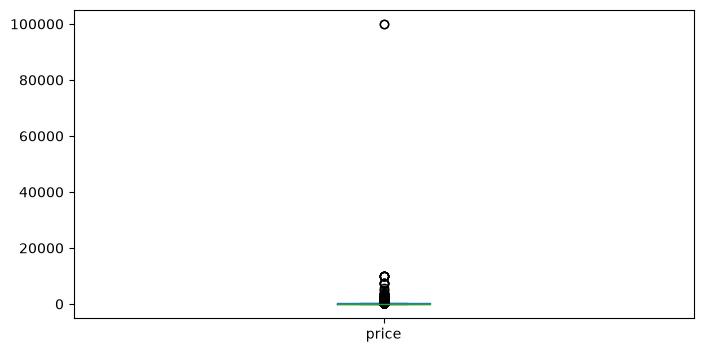

In [53]:
df_ml['price'].plot(
    kind='box',
    figsize=(8, 4)
)

In [54]:
counts = df_ml['neighbourhood'].value_counts()

rare_neighbourhoods = counts[counts < 20].index

df_ml['neighbourhood'] = df_ml['neighbourhood'].replace(
    rare_neighbourhoods, 'Other'
)

Finding the 20 most expensive listings

In [55]:
df_ml.nlargest(20, 'price')[
    ['neighbourhood_group',
     'neighbourhood',
     'room_type',
     'bedrooms',
     'baths',
     'price']
]

,neighbourhood_group,neighbourhood,room_type,bedrooms,baths,price
3995,Brooklyn,Bedford-Stuyvesant,Private room,1,1.0,100000.0
5497,Brooklyn,Bedford-Stuyvesant,Private room,1,1.0,100000.0
906,Manhattan,Midtown,Private room,1,1.0,10000.0
2957,Queens,Long Island City,Entire home/apt,2,1.0,10000.0
3031,Manhattan,Murray Hill,Shared room,4,2.0,10000.0
3145,Manhattan,Midtown,Private room,1,1.0,10000.0
4533,Manhattan,Midtown,Private room,1,1.0,10000.0
6879,Manhattan,Financial District,Entire home/apt,0,1.0,10000.0
10899,Bronx,Longwood,Private room,1,1.0,9994.0
11266,Manhattan,Theater District,Hotel room,1,1.0,7590.0


Counting listings above $999

In [56]:
(df_ml['price'] > 999).sum()

np.int64(197)

Calculating the percentage of listings above $999

In [57]:
(df_ml['price'] > 999).mean() * 100

np.float64(0.9505886894421927)

In [58]:
df_model = df_ml[
    (df_ml['price'] >= 10) &
    (df_ml['price'] <= 999)
].copy()

In [59]:
df_model.shape

(20527, 7)

In [60]:
df_model['price'].describe()

count    20527.000000
mean       160.036294
std        128.100049
min         10.000000
25%         80.000000
50%        125.000000
75%        198.000000
max        999.000000
Name: price, dtype: float64

<Axes: >

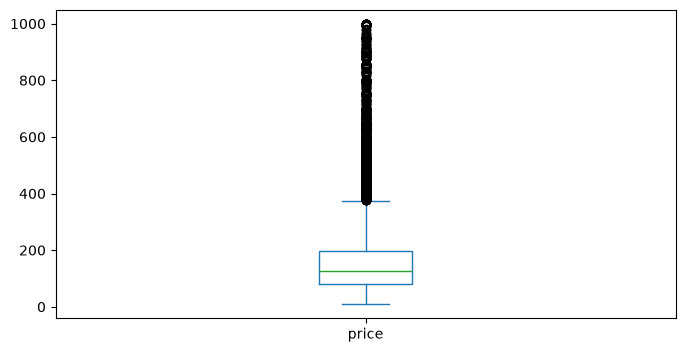

In [61]:
df_model['price'].plot(
    kind='box',
    figsize=(8, 4)
)

Investigating the IQR outliers

In [62]:
Q1 = df_model['price'].quantile(0.25)
Q3 = df_model['price'].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print("Upper limit:", upper_limit)

print("Outliers:", 
      (df_model['price'] > upper_limit).sum())

Upper limit: 375.0
Outliers: 1187


In [63]:
df_model[df_model['price'] > upper_limit][
    ['neighbourhood_group',
     'neighbourhood',
     'room_type',
     'bedrooms',
     'baths',
     'price']
].head(15)

,neighbourhood_group,neighbourhood,room_type,bedrooms,baths,price
22,Manhattan,Upper West Side,Entire home/apt,2,2.0,425.0
52,Manhattan,East Village,Entire home/apt,2,2.0,450.0
69,Queens,South Ozone Park,Entire home/apt,6,4.0,900.0
70,Manhattan,Chelsea,Private room,0,1.0,999.0
74,Queens,Forest Hills,Entire home/apt,3,1.0,418.0
80,Brooklyn,Flatbush,Entire home/apt,5,3.5,460.0
96,Manhattan,Hell's Kitchen,Entire home/apt,1,1.0,428.0
169,Manhattan,Upper East Side,Entire home/apt,3,3.0,950.0
177,Manhattan,East Village,Private room,2,1.0,499.0
188,Brooklyn,Williamsburg,Entire home/apt,2,1.0,390.0


In [64]:
df_analysis = df_ml[df_ml['price'] <= 375]

In [65]:
df_analysis.shape

(19340, 7)

In [66]:
df_analysis['price'].describe()

count    19340.000000
mean       136.014323
std         76.337155
min         10.000000
25%         79.000000
50%        120.000000
75%        179.000000
max        375.000000
Name: price, dtype: float64

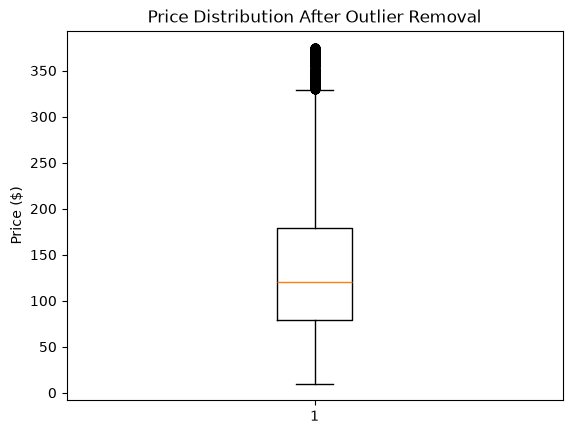

In [67]:
import matplotlib.pyplot as plt

plt.boxplot(df_analysis['price'])
plt.title('Price Distribution After Outlier Removal')
plt.ylabel('Price ($)')
plt.show()

EDA

In [68]:
df_analysis.groupby('neighbourhood_group')['price'].mean().sort_values(ascending=False)

neighbourhood_group
Manhattan        155.692802
Brooklyn         133.893763
Queens           112.456948
Staten Island    110.576923
Bronx            102.182013
Name: price, dtype: float64

In [69]:
df_analysis.groupby('neighbourhood_group')['price'].median().sort_values(ascending=False)

neighbourhood_group
Manhattan        140.0
Brooklyn         120.0
Staten Island     98.0
Queens            95.0
Bronx             89.0
Name: price, dtype: float64

In [72]:
avg_price = df.groupby('neighbourhood_group')['price'].mean()
print(avg_price)

neighbourhood_group
Bronx            118.407798
Brooklyn         187.196647
Manhattan        227.585979
Queens           126.521415
Staten Island    118.780069
Name: price, dtype: float64


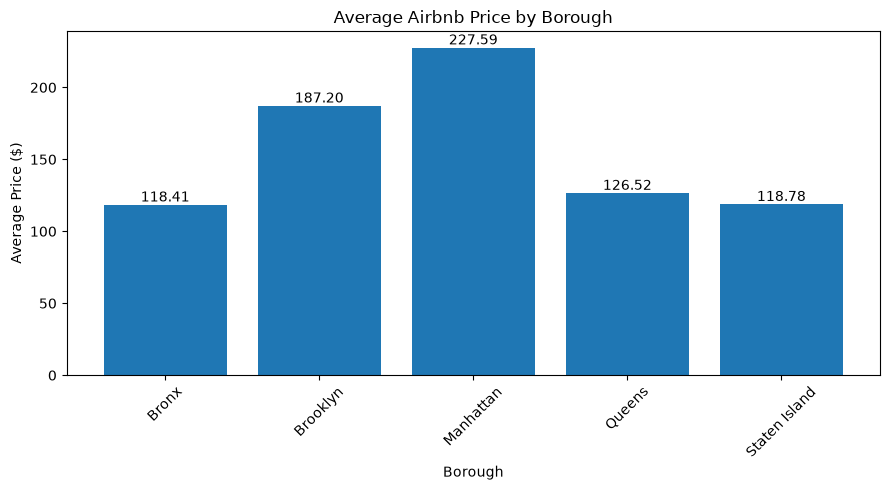

In [73]:
plt.figure(figsize=(9,5))

bars = plt.bar(avg_price.index, avg_price.values)

plt.title('Average Airbnb Price by Borough')
plt.xlabel('Borough')
plt.ylabel('Average Price ($)')
plt.xticks(rotation=45)

plt.bar_label(bars, fmt='%.2f')

plt.tight_layout()
plt.show()

Manhattan has the highest average Airbnb listing price ($155.69), followed by Brooklyn ($133.89). The Bronx has the lowest average price ($102.18). Median prices show a similar pattern, indicating geographical differences in accommodation pricing across NYC.

In [74]:
df_analysis.groupby('room_type')['price'].agg(
    ['count', 'mean', 'median']
).sort_values(by='mean', ascending=False)

,count,mean,median
room_type,,,
Hotel room,89,212.314607,203.0
Entire home/apt,10377,168.760046,150.0
Shared room,284,97.169014,75.0
Private room,8590,96.950175,80.0


Hotel rooms are the most expensive, with an average price of approximately $212 per night.
Entire homes/apartments are the second most expensive, averaging approximately $169.
Private rooms and shared rooms are considerably cheaper, averaging around $97.
Entire homes/apartments account for the largest number of listings (10,377).
Hotel rooms have the fewest listings (89).

Average price by room type

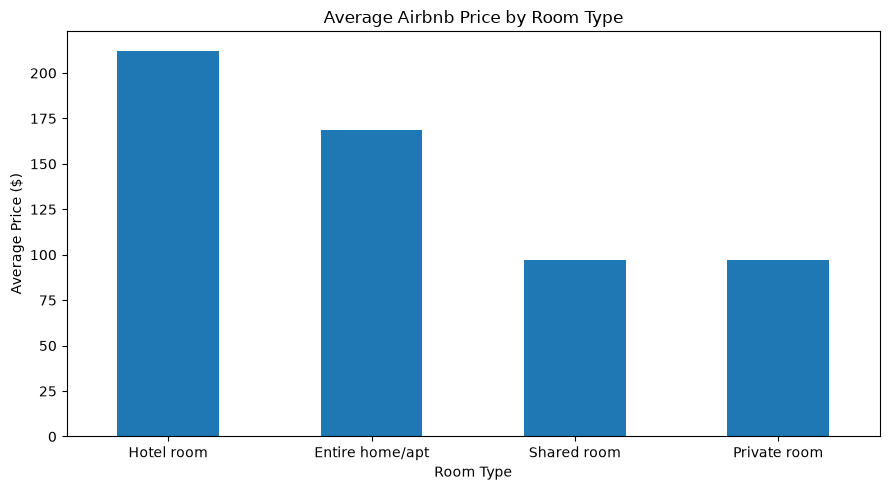

In [75]:
room_price = df_analysis.groupby('room_type')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(9,5))
room_price.plot(kind='bar')

plt.title('Average Airbnb Price by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Average Price ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Number of listings by room type

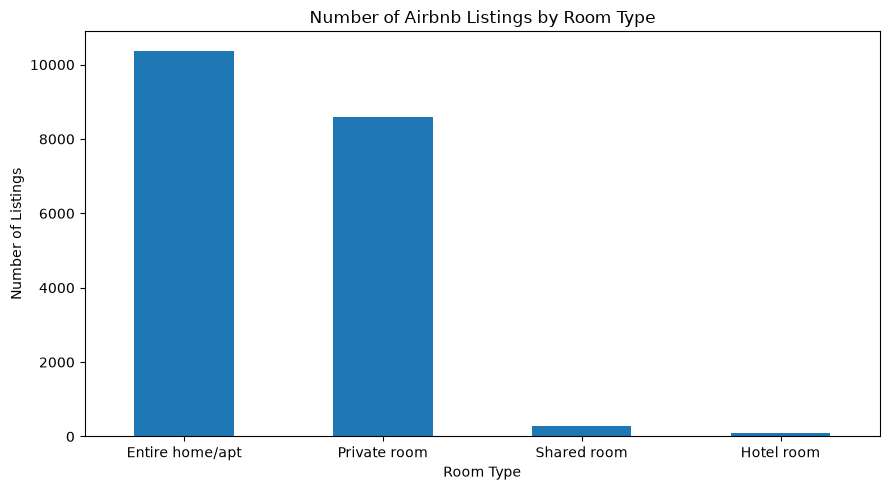

In [76]:
room_count = df_analysis['room_type'].value_counts()

plt.figure(figsize=(9,5))
room_count.plot(kind='bar')

plt.title('Number of Airbnb Listings by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Number of Listings')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Combined statistical summary

In [77]:
df_analysis.groupby('room_type')['price'].agg(
    count='count',
    mean='mean',
    median='median'
).sort_values(by='mean', ascending=False)

,count,mean,median
room_type,,,
Hotel room,89,212.314607,203.0
Entire home/apt,10377,168.760046,150.0
Shared room,284,97.169014,75.0
Private room,8590,96.950175,80.0


In [78]:
df_model = df_analysis.copy()

df_model.info()

<class 'pandas.DataFrame'>
Index: 19340 entries, 0 to 20769
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   neighbourhood_group  19340 non-null  str    
 1   neighbourhood        19340 non-null  str    
 2   room_type            19340 non-null  str    
 3   bedrooms             19340 non-null  int64  
 4   beds                 19340 non-null  int64  
 5   baths                19340 non-null  float64
 6   price                19340 non-null  float64
dtypes: float64(2), int64(2), str(3)
memory usage: 1.2 MB


In [79]:
df_model.isnull().sum()

neighbourhood_group    0
neighbourhood          0
room_type              0
bedrooms               0
beds                   0
baths                  0
price                  0
dtype: int64

In [80]:
X = df_model.drop('price', axis=1)
y = df_model['price']

In [81]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [82]:
X.head()

,bedrooms,beds,baths,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,neighbourhood_Arverne,neighbourhood_Astoria,neighbourhood_Battery Park City,...,neighbourhood_West Brighton,neighbourhood_West Village,neighbourhood_Williamsbridge,neighbourhood_Williamsburg,neighbourhood_Windsor Terrace,neighbourhood_Woodhaven,neighbourhood_Woodside,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,1,1,1.0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,2,1,1.0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,2,1.0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,1,1.0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0,1,1.0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [83]:
X.shape

(19340, 134)

In [84]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [86]:
from sklearn.model_selection import train_test_split

In [85]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [87]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(15472, 134)
(3868, 134)
(15472,)
(3868,)


Training ML model

In [88]:
from sklearn.linear_model import LinearRegression

# Initialize model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](134,)","[ 21.08, 12.15, 5.8 ,..., 20.92,-47.89,-54.84]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](134,)","['bedrooms','beds','baths',...,'room_type_Hotel room', 'room_type_Private room','room_type_Shared room']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,63.93
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,134
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(134)


In [89]:
y_pred = model.predict(X_test)

In [90]:
print(y_pred[:10])

[ 75.24788991 144.3320014  141.88629649  90.63513029 171.1233549
  82.63836063 156.36114756 155.35437407  59.3300371   90.63513029]


In [91]:
print(y_test.head(10).values)

[ 38. 140.  44. 148. 125. 102. 198. 160.  60. 155.]


In [92]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 45.52102784602304
MSE: 3540.694986797198
RMSE: 59.503739267353595
R2 Score: 0.3884198285627227


In [93]:
y_pred = model.predict(X_test)

Actual vs Predicted Price

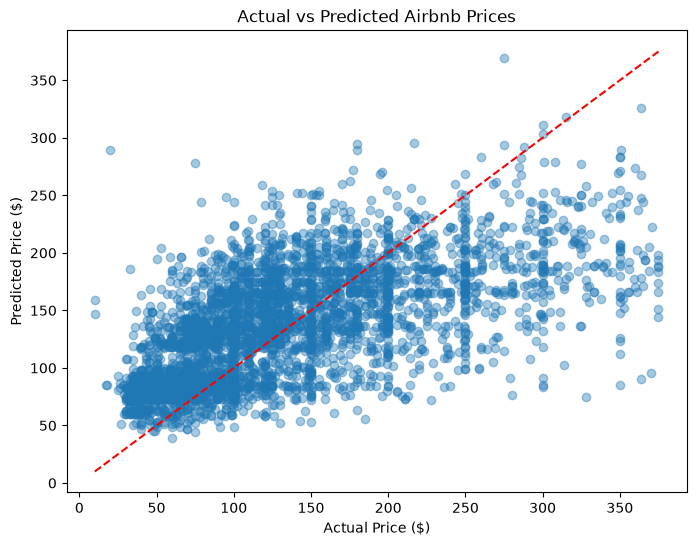

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Airbnb Prices")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

Residual Analysis

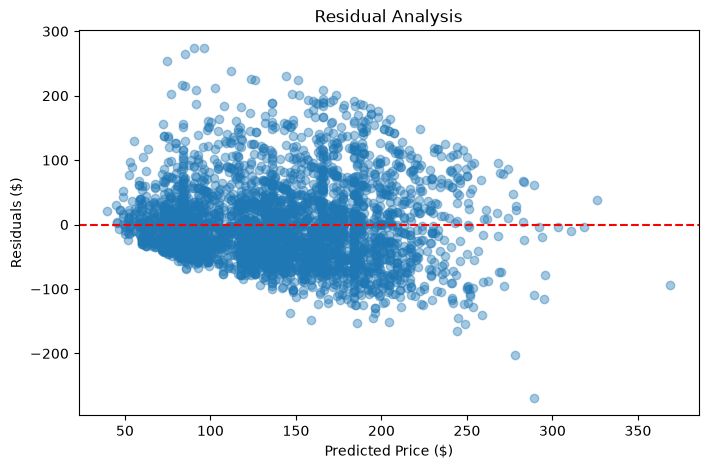

In [95]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals, alpha=0.4)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price ($)")
plt.ylabel("Residuals ($)")
plt.title("Residual Analysis")

plt.show()

Training Random Forest Regressor

In [96]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [97]:
rf_pred = rf_model.predict(X_test)

In [98]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

MAE: 43.108276379361435
MSE: 3368.101918323081
RMSE: 58.03535059188564
R2 Score: 0.41823163070887914


Feature Importance

room_type_Private room              0.337158
bedrooms                            0.131437
beds                                0.103219
baths                               0.069891
neighbourhood_group_Manhattan       0.044982
room_type_Shared room               0.018238
neighbourhood_group_Brooklyn        0.014963
neighbourhood_Hell's Kitchen        0.012414
neighbourhood_Williamsburg          0.011000
neighbourhood_Harlem                0.010592
neighbourhood_Midtown               0.009194
neighbourhood_Washington Heights    0.007803
neighbourhood_East Harlem           0.006918
neighbourhood_Financial District    0.006621
neighbourhood_Upper East Side       0.005934
dtype: float64


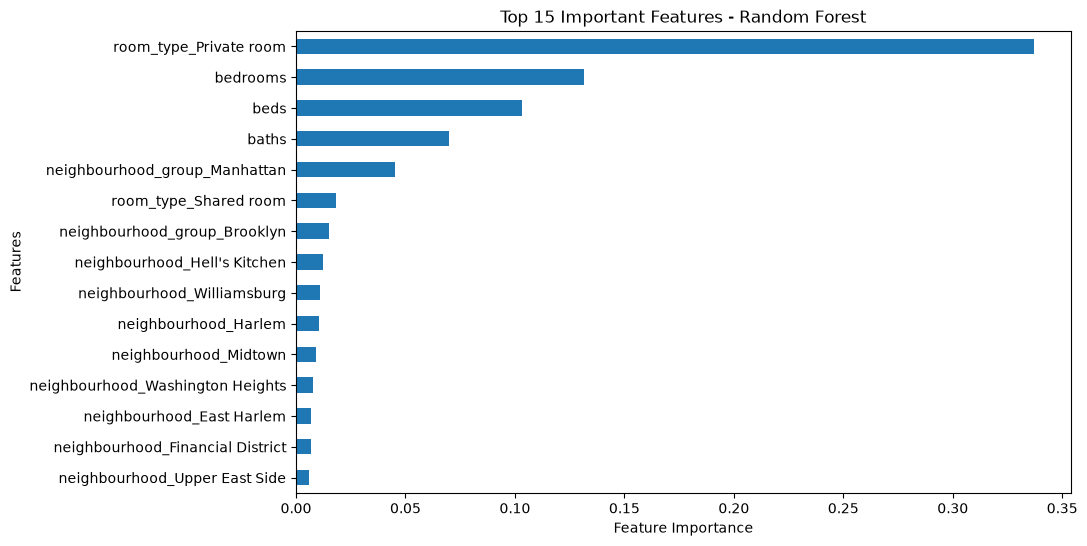

In [99]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
)

importance = importance.sort_values(ascending=False)

# Display top 15 features
print(importance.head(15))

# Visualize
plt.figure(figsize=(10,6))

importance.head(15).sort_values().plot(kind='barh')

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Random Forest")

plt.show()

Hyperparameter tuning

In [100]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

In [101]:
rf = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_s

In [103]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV Score: 0.4260195353077439


Training the tuned model

In [104]:
best_rf = grid_search.best_estimator_

best_rf.fit(X_train, y_train)

y_pred_tuned = best_rf.predict(X_test)

Evaluating the tuned model

In [105]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_tuned)
mse = mean_squared_error(y_test, y_pred_tuned)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_tuned)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 42.7119108489139
MSE: 3259.1928539102532
RMSE: 57.08934098332414
R2 Score: 0.43704336810310207


Training Gradient Boosting

In [106]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

Calculating evaluation metrics

In [107]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("MAE:", mae_gb)
print("MSE:", mse_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

MAE: 44.78541400049348
MSE: 3407.5780373873854
RMSE: 58.374463915203414
R2 Score: 0.4114129660808751


 XGBoost

In [ ]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB 326.8 kB/s eta 0:02:30
   ---------------------------------------- 0.2/48.9 MB 1.6 MB/s eta 0:00:32
   ---------------------------------------- 0.5/48.9 MB 3.0 MB/s eta 0:00:16
    --------------------------------------- 1.0/48.9 MB 4.8 MB/s eta 0:00:10
   - -------------------------------------- 1.3/48.9 MB 5.3 MB/s eta 0:00:09
   - -------------------------------------- 1.9/48.9 MB 5.9 MB/s eta 0:00:08
   -- ------------------------------------- 2.8/48.9 MB 8.0 MB/s eta 0:00:06
   -- ------------------------------------- 3.6/48.9 MB 9.3 MB/s eta 0:00:05
   --- ------------------------------------ 3.9/48.9 MB 8.8 MB/s eta 0:00:06
   --- ------------------------------------ 4.0/48.9 MB 8.2 MB/s eta 0:00:06
   --- -----------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [108]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

In [111]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("MAE:", mae_xgb)
print("MSE:", mse_xgb)
print("RMSE:", rmse_xgb)
print("R2 Score:", r2_xgb)

MAE: 43.56165337587217
MSE: 3284.169460413461
RMSE: 57.3076736608062
R2 Score: 0.43272918759783063


In [112]:
import joblib

joblib.dump(best_rf, 'airbnb_price_model.pkl')

['airbnb_price_model.pkl']

In [113]:
loaded_model = joblib.load('airbnb_price_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [114]:
sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Predicted prices:", sample_prediction)
print("Actual prices:", y_test.iloc[:5].values)

Predicted prices: [ 79.77272036 138.7654315   52.28701207  81.54198995 167.64454977]
Actual prices: [ 38. 140.  44. 148. 125.]


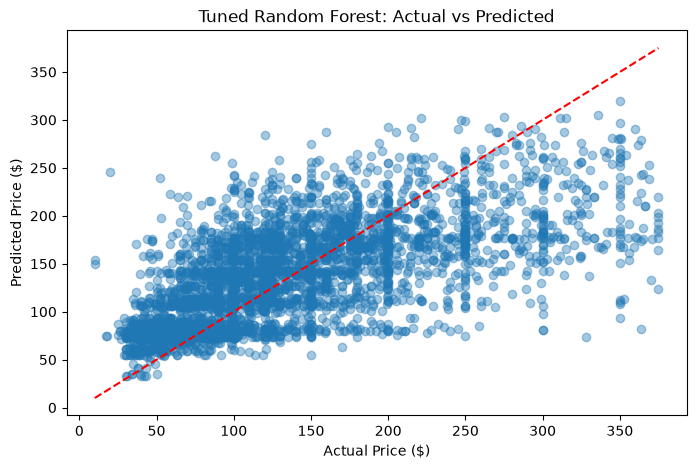

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_tuned, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Tuned Random Forest: Actual vs Predicted")

plt.show()

In [116]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'Tuned Random Forest'],
    'MAE': [45.521, 43.108, 42.712],
    'MSE': [3540.695, 3368.102, 3259.193],
    'RMSE': [59.504, 58.035, 57.089],
    'R2 Score': [0.388, 0.418, 0.437]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,45.521,3540.695,59.504,0.388
1,Random Forest,43.108,3368.102,58.035,0.418
2,Tuned Random Forest,42.712,3259.193,57.089,0.437


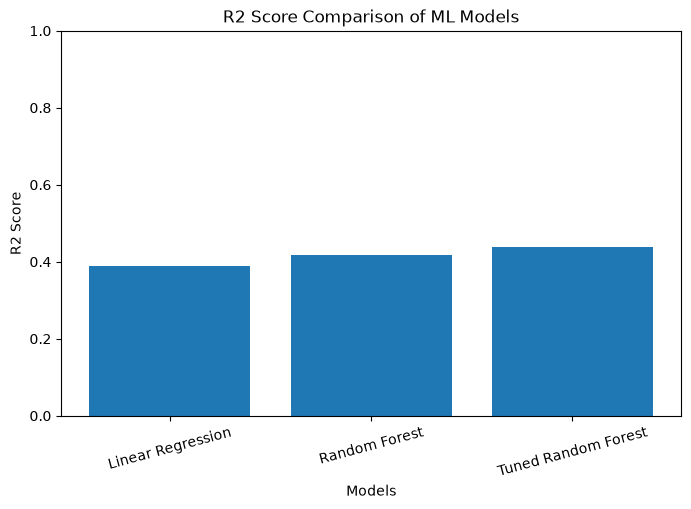

In [117]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(results['Model'], results['R2 Score'])

plt.title('R2 Score Comparison of ML Models')
plt.xlabel('Models')
plt.ylabel('R2 Score')

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

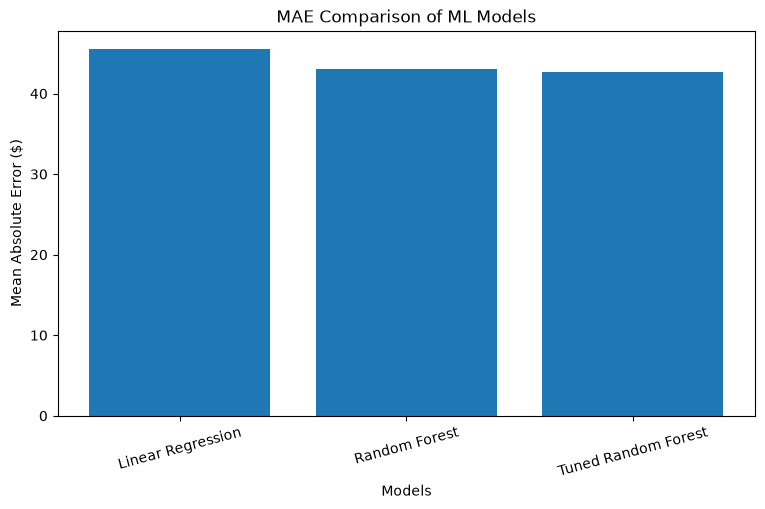

In [118]:
plt.figure(figsize=(9,5))

plt.bar(results['Model'], results['MAE'])

plt.title('MAE Comparison of ML Models')
plt.xlabel('Models')
plt.ylabel('Mean Absolute Error ($)')

plt.xticks(rotation=15)
plt.show()

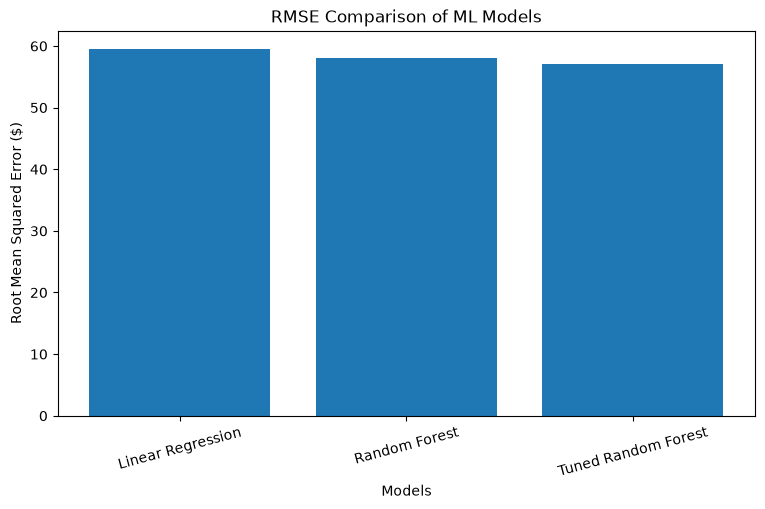

In [119]:
plt.figure(figsize=(9,5))

plt.bar(results['Model'], results['RMSE'])

plt.title('RMSE Comparison of ML Models')
plt.xlabel('Models')
plt.ylabel('Root Mean Squared Error ($)')

plt.xticks(rotation=15)
plt.show()

## Machine Learning Results & Key Findings

Three regression models were developed to predict Airbnb listing prices:

1. Linear Regression
2. Random Forest Regressor
3. Tuned Random Forest Regressor using GridSearchCV

### Model Performance

The Tuned Random Forest achieved the best performance, with:
- MAE: $42.71
- RMSE: $57.09
- R² Score: 0.437

### Key Findings

- Random Forest performed better than Linear Regression.
- Hyperparameter tuning improved the Random Forest model.
- Room type, particularly Private Room, was the most important feature according to the Random Forest feature importance analysis.
- Bedrooms, beds and bathrooms also contributed to price predictions.
- Manhattan location contributed to price variation.

### Conclusion

The Tuned Random Forest Regressor was selected as the final model. Although it outperformed the other tested models, its R² score indicates that additional features and modelling approaches could improve prediction accuracy.

In [121]:
def predict_airbnb_price(neighbourhood_group, neighbourhood,
                         room_type, bedrooms, beds, baths):

    new_data = pd.DataFrame({
        'neighbourhood_group': [neighbourhood_group],
        'neighbourhood': [neighbourhood],
        'room_type': [room_type],
        'bedrooms': [bedrooms],
        'beds': [beds],
        'baths': [baths]
    })

    new_data = pd.get_dummies(new_data)

    new_data = new_data.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    prediction = best_rf.predict(new_data)

    return round(prediction[0], 2)

In [122]:
import joblib

best_rf = joblib.load('airbnb_price_model.pkl')

print(best_rf)

RandomForestRegressor(max_depth=20, min_samples_leaf=2, min_samples_split=5,
                      n_estimators=200, random_state=42)


In [123]:
predict_airbnb_price(
    neighbourhood_group='Manhattan',
    neighbourhood='Harlem',
    room_type='Private room',
    bedrooms=1,
    beds=1,
    baths=1
)

np.float64(87.35)

In [124]:
predict_airbnb_price(
    neighbourhood_group='Brooklyn',
    neighbourhood='Williamsburg',
    room_type='Entire home/apt',
    bedrooms=2,
    beds=2,
    baths=1
)

np.float64(200.83)